In [38]:
"""
โครงงานวิเคราะห์ข้อมูล Spotify - โค้ดสร้างกราฟสำหรับสไลด์นำเสนอ
ไลบรารี: numpy, pandas, matplotlib (ไม่ต้องใช้ scipy / seaborn)

วิธีรัน (VS Code / Terminal):
    1) วางไฟล์นี้ไว้โฟลเดอร์เดียวกับ Spotify_clean.csv
    2) python spotify_charts.py
        (หรือระบุ path เอง:  python spotify_charts.py "C:/Users/User/Desktop/Spotify_clean.csv")
    3) ได้รูป PNG ในโฟลเดอร์ charts/ นำไปแทรกสไลด์ได้เลย
"""

import math
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ------------------------------------------------------------------
# 0) ตั้งค่าหน้าตากราฟ (ธีมเขียว-ดำแบบ Spotify) + ฟอนต์ไทย
# ------------------------------------------------------------------
BG = "#121212"        # พื้นหลัง (ดำ)
PANEL = "#1E1E1E"     # พื้นหลังตาราง
TEXT = "#FFFFFF"
MUTED = "#B3B3B3"
GREEN = "#1DB954"     # เขียว Spotify
PINK = "#E8115B"      # สีเน้น (กลุ่ม / ค่าผิดปกติ)
GRID = "#2E2E2E"

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Leelawadee UI", "Tahoma", "TH Sarabun New", "Thonburi",
                        "Noto Sans Thai", "Loma", "DejaVu Sans"],
    "axes.unicode_minus": False,
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": TEXT,
    "axes.titlesize": 20, "axes.titleweight": "bold",
    "axes.labelsize": 14, "xtick.labelsize": 13, "ytick.labelsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True,
})
FIGSIZE = (12, 6.5)   # สัดส่วนใกล้ 16:9 เหมาะกับสไลด์
DPI = 200

OUT_DIR = "charts"
os.makedirs(OUT_DIR, exist_ok=True)

# ------------------------------------------------------------------
# 1) อ่านข้อมูล + ตรวจสอบ/ทำความสะอาด
# ------------------------------------------------------------------
def find_csv(name="Spotify_clean.csv"):
    """หาไฟล์ csv ได้ทั้งตอนรันเป็น .py และตอนรันใน Jupyter/VS Code Notebook"""
    candidates = []
    if len(sys.argv) > 1 and sys.argv[1].lower().endswith(".csv"):
        candidates.append(sys.argv[1])
    try:
        base = os.path.dirname(os.path.abspath(__file__))   # รันเป็นไฟล์ .py
    except NameError:
        base = os.getcwd()                                  # รันใน notebook ไม่มี __file__
    candidates += [os.path.join(base, name), os.path.join(os.getcwd(), name)]
    for c in candidates:
        if os.path.exists(c):
            return c
    raise FileNotFoundError(
        f"ไม่พบไฟล์ {name} -> วางไว้โฟลเดอร์เดียวกับสคริปต์/notebook "
        f"หรือแก้ path ด้านล่างเอง\nที่ค้นหา: {candidates}")


path = find_csv("C:/Users/dream/Downloads/Spotify_clean.csv")
# ถ้ายังหาไม่เจอ ให้ใส่ path เต็มเอง เช่น: path = r"C:\Users\dream\Desktop\Spotify_clean.csv"

df = pd.read_csv(path)
df.columns = df.columns.str.strip()

print("ขนาดข้อมูล (แถว, คอลัมน์):", df.shape)
print("\nชนิดข้อมูล:\n", df.dtypes)
print("\nค่าสูญหายรายคอลัมน์:\n", df.isna().sum())
print("\nข้อมูลซ้ำ:", df.duplicated().sum(), "แถว")
print("\nจำนวนศิลปินแต่ละประเภท:\n", df["Artist Type"].value_counts())

df = df.drop_duplicates().dropna(subset=["Total Streams (in millions)"])

# เปลี่ยนหน่วย "ล้านสตรีม" -> "พันล้านสตรีม" เพื่อให้ตัวเลขบนแกนอ่านง่าย
TOTAL, LEAD, FEAT, SOLO = "Total", "Lead", "Feature", "Solo"
df[TOTAL] = df["Total Streams (in millions)"] / 1000
df[LEAD] = df["Lead Streams (in millions)"] / 1000
df[FEAT] = df["Feature Streams (in millions)"] / 1000
df[SOLO] = df["Solo Streams (in millions)"] / 1000
UNIT = "พันล้านสตรีม"

LABELS_TH = {TOTAL: "ยอดสตรีมรวม\n(Total)", LEAD: "เพลงหลัก\n(Lead)",
             FEAT: "ร่วมร้อง\n(Feature)", SOLO: "ร้องเดี่ยว\n(Solo)"}
TYPE_TH = {"Solo": "ศิลปินเดี่ยว (Solo)", "Group": "ศิลปินกลุ่ม (Group)"}

summary = []   # เก็บข้อความสรุปไว้เขียน summary.txt


def save(fig, name):
    fig.savefig(os.path.join(OUT_DIR, name), dpi=DPI, bbox_inches="tight")
    plt.close(fig)
    print("บันทึกแล้ว:", os.path.join(OUT_DIR, name))


def iqr_outliers(s):
    """กฎ 1.5 x IQR -> คืนค่า (จำนวนค่าผิดปกติ, เส้นขอบบน)"""
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    upper = q3 + 1.5 * (q3 - q1)
    lower = q1 - 1.5 * (q3 - q1)
    return int(((s > upper) | (s < lower)).sum()), upper


def welch_t(a, b):
    """Welch t-test (ประมาณ p ด้วยการแจกแจงปกติ เพราะ n มาก) ไม่ต้องใช้ scipy"""
    se = math.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    t = (a.mean() - b.mean()) / se
    p = math.erfc(abs(t) / math.sqrt(2))
    return t, p


def fmt_p(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"


def strength(r):
    r = abs(r)
    if r < 0.1:
        return "แทบไม่มี"
    if r < 0.3:
        return "อ่อน"
    if r < 0.5:
        return "ปานกลางค่อนต่ำ"
    if r < 0.7:
        return "ปานกลาง"
    return "สูง"


# ------------------------------------------------------------------
# 2) สไลด์ 6: ตารางสถิติเชิงพรรณนา
# ------------------------------------------------------------------
cols = [TOTAL, LEAD, FEAT, SOLO]
rows = []
for c in cols:
    n_out, _ = iqr_outliers(df[c])
    rows.append([LABELS_TH[c].replace("\n", " "),
                 f"{df[c].mean():.2f}", f"{df[c].median():.2f}",
                 f"{df[c].std(ddof=1):.2f}",
                 f"{df[c].min():.2f}", f"{df[c].max():.2f}", str(n_out)])

stats_df = pd.DataFrame(rows, columns=["ตัวแปร", "ค่าเฉลี่ย", "มัธยฐาน", "SD", "ต่ำสุด",
                                       "สูงสุด", "ค่าผิดปกติ"])
stats_df.to_csv(os.path.join(OUT_DIR, "00_stats_table.csv"), index=False, encoding="utf-8-sig")
print("\nสถิติเชิงพรรณนา (หน่วย: พันล้านสตรีม)\n", stats_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 3.6))
ax.axis("off")
tbl = ax.table(cellText=stats_df.values, colLabels=stats_df.columns, loc="center",
               cellLoc="center",
               colWidths=[0.27, 0.11, 0.11, 0.1, 0.1, 0.11, 0.2])
tbl.auto_set_font_size(False)
tbl.set_fontsize(14)
tbl.scale(1, 2.2)
for (r, c), cell in tbl.get_celld().items():
    cell.set_edgecolor(GRID)
    if r == 0:
        cell.set_facecolor(GREEN)
        cell.get_text().set_color("#000000")
        cell.get_text().set_weight("bold")
    else:
        cell.set_facecolor(PANEL)
        cell.get_text().set_color(TEXT)
ax.set_title(f"สถิติเชิงพรรณนาของยอดสตรีม (หน่วย: {UNIT}, n = {len(df)} ศิลปิน)",
             pad=12, color=TEXT)
save(fig, "00_stats_table.png")

# ------------------------------------------------------------------
# 3) ข้อ 1: แผนภาพกล่อง (Boxplot)
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=FIGSIZE)
data = [df[c] for c in cols]
bp = ax.boxplot(data, patch_artist=True, widths=0.55, showfliers=True,
                flierprops=dict(marker="o", markersize=4, markerfacecolor=PINK,
                                markeredgecolor="none", alpha=0.6),
                medianprops=dict(color="#FFFFFF", linewidth=2.5),
                whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED),
                boxprops=dict(edgecolor=MUTED))
for patch in bp["boxes"]:
    patch.set_facecolor(GREEN)
    patch.set_alpha(0.85)

Y_CAP = 60
ax.set_ylim(0, Y_CAP)
ticklabels = []
for c in cols:
    n_out, _ = iqr_outliers(df[c])
    ticklabels.append(f"{LABELS_TH[c]}\nค่าผิดปกติ {n_out} คน")
    n_off = int((df[c] > Y_CAP).sum())
    if n_off:
        ax.annotate(f"อีก {n_off} คนสูงกว่า {Y_CAP} (ไม่แสดง)", xy=(cols.index(c) + 1, Y_CAP),
                    xytext=(0, 6), textcoords="offset points", ha="center",
                    va="bottom", color=PINK, fontsize=11)
ax.set_xticks(range(1, len(cols) + 1), ticklabels)
ax.set_ylabel(f"ยอดสตรีม ({UNIT})")
ax.set_title("ยอดสตรีมกระจายแบบเบ้ขวา: ศิลปินส่วนน้อยมียอดสูงมาก", pad=34)
ax.grid(axis="x", visible=False)
save(fig, "01_boxplot.png")

med_tot, mean_tot = df[TOTAL].median(), df[TOTAL].mean()
summary.append(f"[ข้อ 1] ยอดรวม ค่าเฉลี่ย {mean_tot:.2f} > มัธยฐาน {med_tot:.2f} {UNIT} "
               f"(เบ้ขวา) ค่าผิดปกติ Total = {iqr_outliers(df[TOTAL])[0]} คน")

# ------------------------------------------------------------------
# 4) ข้อ 2: กราฟแท่งเปรียบเทียบ Solo vs Group
# ------------------------------------------------------------------
solo = df[df["Artist Type"] == "Solo"]
group = df[df["Artist Type"] == "Group"]
metrics = [LEAD, FEAT]
x = np.arange(len(metrics))
w = 0.36

fig, ax = plt.subplots(figsize=FIGSIZE)
for i, (g, color) in enumerate([(solo, GREEN), (group, PINK)]):
    means = [g[m].mean() for m in metrics]
    sems = [g[m].std(ddof=1) / math.sqrt(len(g)) for m in metrics]
    medians = [g[m].median() for m in metrics]
    pos = x + (i - 0.5) * w
    ax.bar(pos, means, w, color=color, label=f"{TYPE_TH[g['Artist Type'].iloc[0]]}  (n = {len(g)})",
           yerr=sems, capsize=6, error_kw=dict(ecolor=TEXT, lw=1.5))
    ax.scatter(pos, medians, marker="D", s=70, color="#FFFFFF", zorder=5,
               label="มัธยฐาน" if i == 0 else None)
    for px, m in zip(pos, means):
        ax.text(px, m + 0.9, f"{m:.1f}", ha="center", va="bottom", fontsize=14,
                fontweight="bold", color=TEXT)

t_lead, p_lead = welch_t(solo[LEAD], group[LEAD])
t_feat, p_feat = welch_t(solo[FEAT], group[FEAT])
pct_lead = (solo[LEAD].mean() / group[LEAD].mean() - 1) * 100
sig = "แตกต่างอย่างมีนัยสำคัญ" if p_lead < 0.05 else "ไม่แตกต่างอย่างมีนัยสำคัญ"
direction = "สูงกว่า" if pct_lead >= 0 else "ต่ำกว่า"

ax.set_xticks(x, ["ยอดเพลงหลัก (Lead)", "ยอดร่วมร้อง (Feature)"])
ax.set_ylabel(f"ค่าเฉลี่ยยอดสตรีม ({UNIT})")
ax.set_ylim(0, max(solo[LEAD].mean(), group[LEAD].mean()) * 1.3)
ax.set_title(f"เพลงหลัก: ศิลปินเดี่ยว{direction}กลุ่ม {abs(pct_lead):.1f}% ({sig})", pad=14)
ax.legend(frameon=False, fontsize=12, loc="upper right")
ax.text(0.01, -0.13,
        f"แถบ = ± SE | Welch t-test: Lead {fmt_p(p_lead)}, Feature {fmt_p(p_feat)}",
        transform=ax.transAxes, color=MUTED, fontsize=11)
ax.grid(axis="x", visible=False)
save(fig, "02_bar_solo_group.png")

summary.append(
    f"[ข้อ 2] Lead เฉลี่ย เดี่ยว {solo[LEAD].mean():.2f} vs กลุ่ม {group[LEAD].mean():.2f} {UNIT} "
    f"(เดี่ยว{direction} {abs(pct_lead):.1f}%, t = {t_lead:.2f}, p ≈ {p_lead:.3f} -> {sig}) | "
    f"มัธยฐาน เดี่ยว {solo[LEAD].median():.2f} vs กลุ่ม {group[LEAD].median():.2f}")
summary.append(
    f"[วัตถุประสงค์ 1] Feature เฉลี่ย เดี่ยว {solo[FEAT].mean():.2f} vs กลุ่ม {group[FEAT].mean():.2f} "
    f"{UNIT} (t = {t_feat:.2f}, {fmt_p(p_feat)})")

# ------------------------------------------------------------------
# 5) ข้อ 3: กราฟการกระจาย Lead vs Feature + สัมประสิทธิ์สหสัมพันธ์
# ------------------------------------------------------------------
r_p = df[LEAD].corr(df[FEAT])
r_s = df[LEAD].corr(df[FEAT], method="spearman")
slope, intercept = np.polyfit(df[LEAD], df[FEAT], 1)

fig, ax = plt.subplots(figsize=FIGSIZE)
for g, color in [(solo, GREEN), (group, PINK)]:
    ax.scatter(g[LEAD], g[FEAT], s=28, alpha=0.65, color=color, edgecolors="none",
               label=TYPE_TH[g["Artist Type"].iloc[0]])
xs = np.linspace(df[LEAD].min(), df[LEAD].max(), 100)
ax.plot(xs, slope * xs + intercept, color="#FFFFFF", lw=2, ls="--", label="เส้นแนวโน้ม")

notable = pd.concat([df.nlargest(2, LEAD), df.nlargest(2, FEAT)]).drop_duplicates("Artist Name")
for _, row in notable.iterrows():
    ax.annotate(row["Artist Name"], (row[LEAD], row[FEAT]), xytext=(8, 6),
                textcoords="offset points", fontsize=11, color=TEXT)

ax.set_xlabel(f"Lead Streams ({UNIT})")
ax.set_ylabel(f"Feature Streams ({UNIT})")
ax.set_title(f"Lead กับ Feature: สพันธ์กัน{strength(r_p)} (r = {r_p:.2f})", pad=14)
ax.legend(frameon=False, fontsize=12, loc="upper left")
ax.text(0.98, 0.55, f"Pearson r = {r_p:.2f}  (r² = {r_p**2:.2f})\nSpearman rs = {r_s:.2f}",
        transform=ax.transAxes, ha="right", fontsize=14, color=TEXT,
        bbox=dict(boxstyle="round,pad=0.5", fc=PANEL, ec=GRID))
save(fig, "03_scatter.png")

summary.append(
    f"[ข้อ 3] Lead เฉลี่ย {df[LEAD].mean():.2f} vs Feature เฉลี่ย {df[FEAT].mean():.2f} {UNIT} "
    f"(Lead สูงกว่า {df[LEAD].mean() / df[FEAT].mean():.1f} เท่า) | "
    f"Pearson r = {r_p:.3f} (r² = {r_p**2:.3f}, ความสัมพันธ์{strength(r_p)}) | "
    f"Spearman rs = {r_s:.3f}")

# ------------------------------------------------------------------
# 6) ข้อ 4: กราฟเส้น ค่าเฉลี่ยยอดรวมตามปีเปิดตัว (Debut Year)
# ------------------------------------------------------------------
yearly = df.groupby("Debut Year")[TOTAL].agg(["mean", "count"])
r_year = df["Debut Year"].corr(df[TOTAL])
sl, ic = np.polyfit(df["Debut Year"], df[TOTAL], 1)

fig, (ax, ax2) = plt.subplots(2, 1, figsize=FIGSIZE, sharex=True,
                              gridspec_kw={"height_ratios": [3.2, 1], "hspace": 0.08})
ax.plot(yearly.index, yearly["mean"], color=GREEN, lw=2.5, marker="o", ms=5,
        label="ค่าเฉลี่ยรายปี")
ax.plot(yearly.index, sl * yearly.index + ic, color="#FFFFFF", ls="--", lw=2,
        label=f"เส้นแนวโน้ม (r = {r_year:.2f})")
ax.set_ylabel(f"ค่าเฉลี่ยยอดรวม ({UNIT})")
ax.legend(frameon=False, fontsize=12, loc="upper left")
ax.set_title(f"ปีเปิดตัวกับยอดรวม: ความสัมพันธ์{strength(r_year)} (r = {r_year:.2f})", pad=14)

ax2.bar(yearly.index, yearly["count"], color=MUTED, width=0.8)
ax2.set_ylabel("จำนวน\nศิลปิน")
ax2.set_xlabel("ปีเปิดตัว (Debut Year)")
ax2.grid(axis="x", visible=False)
ax2.text(0.01, 0.78, "ปีที่มีศิลปินน้อย (1-2 คน) ค่าเฉลี่ยจะแกว่งมาก", transform=ax2.transAxes,
         color=MUTED, fontsize=11)
save(fig, "04_line_debut.png")

best = yearly[yearly["count"] >= 5]["mean"].idxmax()
summary.append(
    f"[ข้อ 4] ปีเปิดตัว vs ยอดรวม r = {r_year:.3f} ({strength(r_year)}), เส้นแนวโน้มลาด "
    f"{sl * 10:+.2f} {UNIT} ต่อทศวรรษ | ปีที่ค่าเฉลี่ยสูงสุด (เฉพาะปีที่มี ≥5 คน): "
    f"{best} ({yearly.loc[best, 'mean']:.1f} {UNIT})")

# ------------------------------------------------------------------
# 7) บันทึกข้อความสรุป
# ------------------------------------------------------------------
with open(os.path.join(OUT_DIR, "summary.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(summary))
print("\n" + "\n".join(summary))
print("\nเสร็จแล้ว! ดูรูปในโฟลเดอร์:", os.path.abspath(OUT_DIR))

ขนาดข้อมูล (แถว, คอลัมน์): (500, 14)

ชนิดข้อมูล:
 Artist Name                                str
Sex                                        str
Country of Origin                          str
Primary Language                           str
Primary Genre                              str
Artist Type                                str
Debut Year                               int64
Total Streams (in millions)            float64
Lead Streams (in millions)             float64
Feature Streams (in millions)          float64
Solo Streams (in millions)             float64
% of Solo Streams                      float64
Collaborative Streams (in millions)    float64
% of Collaborative Streams             float64
dtype: object

ค่าสูญหายรายคอลัมน์:
 Artist Name                            0
Sex                                    0
Country of Origin                      0
Primary Language                       0
Primary Genre                          0
Artist Type                            0
Debut Ye

In [4]:
import subprocess

# บันทึกข้อความสรุป... (โค้ดเดิมของคุณ)
with open(os.path.join(OUT_DIR, "summary.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(summary))
print("\n" + "\n".join(summary))

# --- เพิ่มส่วนนี้เข้าไป เพื่อสั่งให้มันเปิดโฟลเดอร์ขึ้นมาโชว์ทันทีอัตโนมัติ ---
folder_path = os.path.abspath(OUT_DIR)
print("\nเสร็จแล้ว! กำลังเปิดโฟลเดอร์:", folder_path)

try:
    # สำหรับ Windows จะสั่งเปิดหน้าต่างขึ้นมาทันที
    os.startfile(folder_path)
except Exception:
    pass


[ข้อ 1] ยอดรวม ค่าเฉลี่ย 16.82 > มัธยฐาน 11.92 พันล้านสตรีม (เบ้ขวา) ค่าผิดปกติ Total = 49 คน
[ข้อ 2] Lead เฉลี่ย เดี่ยว 12.40 vs กลุ่ม 11.37 พันล้านสตรีม (เดี่ยวสูงกว่า 9.1%, t = 1.06, p ≈ 0.291 -> ไม่แตกต่างอย่างมีนัยสำคัญ) | มัธยฐาน เดี่ยว 8.57 vs กลุ่ม 8.86
[วัตถุประสงค์ 1] Feature เฉลี่ย เดี่ยว 5.62 vs กลุ่ม 1.92 พันล้านสตรีม (t = 8.52, p < 0.001)
[ข้อ 3] Lead เฉลี่ย 12.14 vs Feature เฉลี่ย 4.68 พันล้านสตรีม (Lead สูงกว่า 2.6 เท่า) | Pearson r = 0.317 (r² = 0.100, ความสัมพันธ์ปานกลางค่อนต่ำ) | Spearman rs = -0.109
[ข้อ 4] ปีเปิดตัว vs ยอดรวม r = 0.068 (แทบไม่มี), เส้นแนวโน้มลาด +0.76 พันล้านสตรีม ต่อทศวรรษ | ปีที่ค่าเฉลี่ยสูงสุด (เฉพาะปีที่มี ≥5 คน): 2013 (25.9 พันล้านสตรีม)

เสร็จแล้ว! กำลังเปิดโฟลเดอร์: c:\Users\dream\AppData\Local\Programs\Microsoft VS Code\charts


In [5]:
# บันทึกข้อความสรุปและเปิดโฟลเดอร์อัตโนมัติ
with open(os.path.join(OUT_DIR, "summary.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(summary))
print("\n" + "\n".join(summary))

folder_path = os.path.abspath(OUT_DIR)
print("\nเสร็จแล้ว! กำลังเปิดโฟลเดอร์:", folder_path)
try:
    os.startfile(folder_path)
except Exception:
    pass


[ข้อ 1] ยอดรวม ค่าเฉลี่ย 16.82 > มัธยฐาน 11.92 พันล้านสตรีม (เบ้ขวา) ค่าผิดปกติ Total = 49 คน
[ข้อ 2] Lead เฉลี่ย เดี่ยว 12.40 vs กลุ่ม 11.37 พันล้านสตรีม (เดี่ยวสูงกว่า 9.1%, t = 1.06, p ≈ 0.291 -> ไม่แตกต่างอย่างมีนัยสำคัญ) | มัธยฐาน เดี่ยว 8.57 vs กลุ่ม 8.86
[วัตถุประสงค์ 1] Feature เฉลี่ย เดี่ยว 5.62 vs กลุ่ม 1.92 พันล้านสตรีม (t = 8.52, p < 0.001)
[ข้อ 3] Lead เฉลี่ย 12.14 vs Feature เฉลี่ย 4.68 พันล้านสตรีม (Lead สูงกว่า 2.6 เท่า) | Pearson r = 0.317 (r² = 0.100, ความสัมพันธ์ปานกลางค่อนต่ำ) | Spearman rs = -0.109
[ข้อ 4] ปีเปิดตัว vs ยอดรวม r = 0.068 (แทบไม่มี), เส้นแนวโน้มลาด +0.76 พันล้านสตรีม ต่อทศวรรษ | ปีที่ค่าเฉลี่ยสูงสุด (เฉพาะปีที่มี ≥5 คน): 2013 (25.9 พันล้านสตรีม)

เสร็จแล้ว! กำลังเปิดโฟลเดอร์: c:\Users\dream\AppData\Local\Programs\Microsoft VS Code\charts


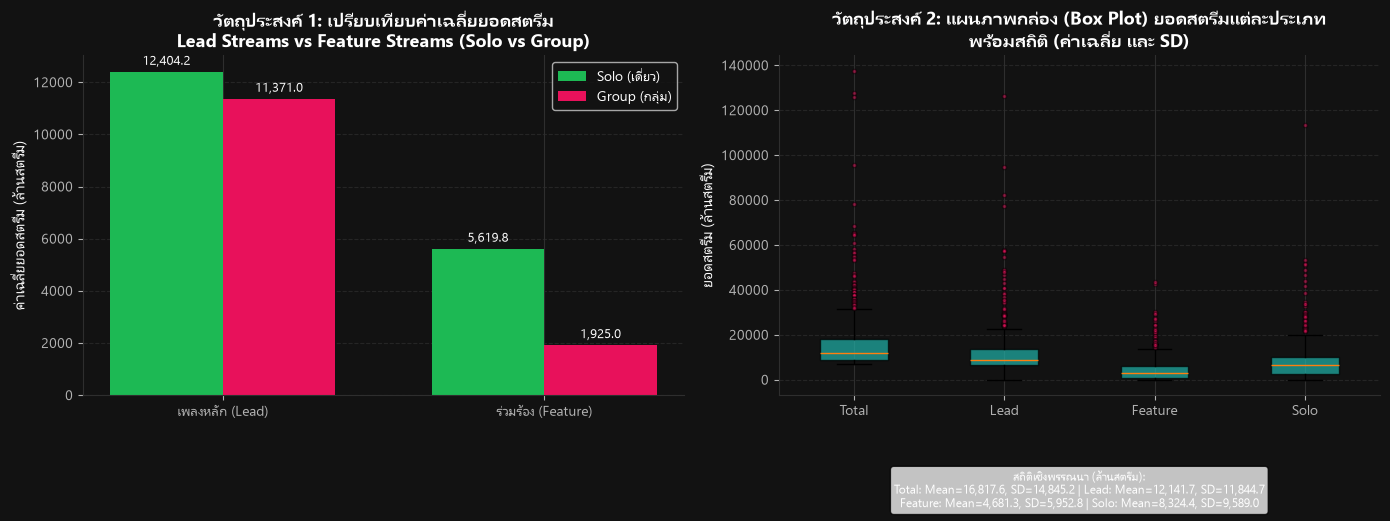

In [9]:
import os
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ------------------------------------------------------------------
# 1) อ่านข้อมูล Spotify_clean.csv
# ------------------------------------------------------------------
# ใส่ path เต็มของไฟล์ CSV ในเครื่องคุณตรงนี้ได้เลยครับ
path = r"C:\Users\dream\Desktop\Spotify_clean.csv"

try:
    df = pd.read_csv(path)
except FileNotFoundError:
    # เผื่อถ้าหาบน Desktop ไม่เจอ จะลองค้นหาในโฟลเดอร์ปัจจุบันแทน
    path = "Spotify_clean.csv"
    df = pd.read_csv("C:/Users/dream/Downloads/Spotify_clean.csv")

df.columns = df.columns.str.strip()

# ทำความสะอาดข้อมูลเบื้องต้น
df = df.drop_duplicates().dropna(subset=["Total Streams (in millions)"])

# ------------------------------------------------------------------
# 2) ตั้งค่าฟอนต์และธีมสำหรับแสดงผล
# ------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Leelawadee UI", "Tahoma", "TH Sarabun New", "Thonburi", "Noto Sans Thai", "DejaVu Sans"],
    "axes.unicode_minus": False,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

# ------------------------------------------------------------------
# 3) สร้างกราฟแสดงผลสำหรับวัตถุประสงค์ข้อที่ 1 และ 2
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# ==================================================================
# วัตถุประสงค์ข้อที่ 1: เปรียบเทียบค่าเฉลี่ย Lead Streams และ Feature Streams
# ระหว่าง ศิลปินเดี่ยว (Solo) และ ศิลปินกลุ่ม (Group)
# ==================================================================
solo = df[df["Artist Type"] == "Solo"]
group = df[df["Artist Type"] == "Group"]

metrics = ["Lead Streams (in millions)", "Feature Streams (in millions)"]
x = np.arange(len(metrics))
width = 0.35

mean_solo = [solo[m].mean() for m in metrics]
mean_group = [group[m].mean() for m in metrics]

ax1 = axes[0]
rects1 = ax1.bar(x - width/2, mean_solo, width, label='Solo (เดี่ยว)', color='#1DB954')
rects2 = ax1.bar(x + width/2, mean_group, width, label='Group (กลุ่ม)', color='#E8115B')

ax1.set_ylabel('ค่าเฉลี่ยยอดสตรีม (ล้านสตรีม)')
ax1.set_title('วัตถุประสงค์ 1: เปรียบเทียบค่าเฉลี่ยยอดสตรีม\nLead Streams vs Feature Streams (Solo vs Group)', fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(['เพลงหลัก (Lead)', 'ร่วมร้อง (Feature)'])
ax1.legend()
ax1.grid(axis='y', linestyle='--', alpha=0.7)

# ตัวเลขบนตัวแท่งกราฟ
for rect in rects1 + rects2:
    height = rect.get_height()
    ax1.annotate(f'{height:,.1f}',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontsize=9)

# ==================================================================
# วัตถุประสงค์ข้อที่ 2: แผนภาพกล่อง (Box Plot) แสดงสัดส่วนการกระจาย
# พร้อมแสดงค่าเฉลี่ย (Mean) และส่วนเบี่ยงเบนมาตรฐาน (SD)
# ==================================================================
stream_cols = [
    "Total Streams (in millions)",
    "Lead Streams (in millions)",
    "Feature Streams (in millions)",
    "Solo Streams (in millions)"
]
box_labels = ["Total", "Lead", "Feature", "Solo"]
data_to_plot = [df[col].dropna() for col in stream_cols]

ax2 = axes[1]
# แก้ไขใช้ tick_labels แทน labels ตรงนี้ครับ
bp = ax2.boxplot(data_to_plot, patch_artist=True, tick_labels=box_labels,
                 flierprops=dict(marker='o', markersize=3, alpha=0.5, markerfacecolor='#E8115B'))

# ตกแต่งสีกล่อง
for box in bp['boxes']:
    box.set_facecolor('#20B2AA')
    box.set_alpha(0.7)

ax2.set_ylabel('ยอดสตรีม (ล้านสตรีม)')
ax2.set_title('วัตถุประสงค์ 2: แผนภาพกล่อง (Box Plot) ยอดสตรีมแต่ละประเภท\nพร้อมสถิติ (ค่าเฉลี่ย และ SD)', fontweight='bold')
ax2.grid(axis='y', linestyle='--', alpha=0.7)

# คำนวณและแสดงค่าทางสถิติ (Mean & SD) ด้านล่างกราฟ Box Plot
stats_text = []
for col_name, short_label in zip(stream_cols, box_labels):
    m = df[col_name].mean()
    sd = df[col_name].std()
    stats_text.append(f"{short_label}: Mean={m:,.1f}, SD={sd:,.1f}")

text_str = "สถิติเชิงพรรณนา (ล้านสตรีม):\n" + " | ".join(stats_text[:2]) + "\n" + " | ".join(stats_text[2:])
ax2.text(0.5, -0.22, text_str, transform=ax2.transAxes, ha='center', va='top',
         fontsize=8.5, bbox=dict(boxstyle='round', facecolor='#f0f0f0', alpha=0.8))

plt.tight_layout()

# แสดงรูปภาพกราฟออกมาบนหน้าจอ Notebook ทันที
plt.show()

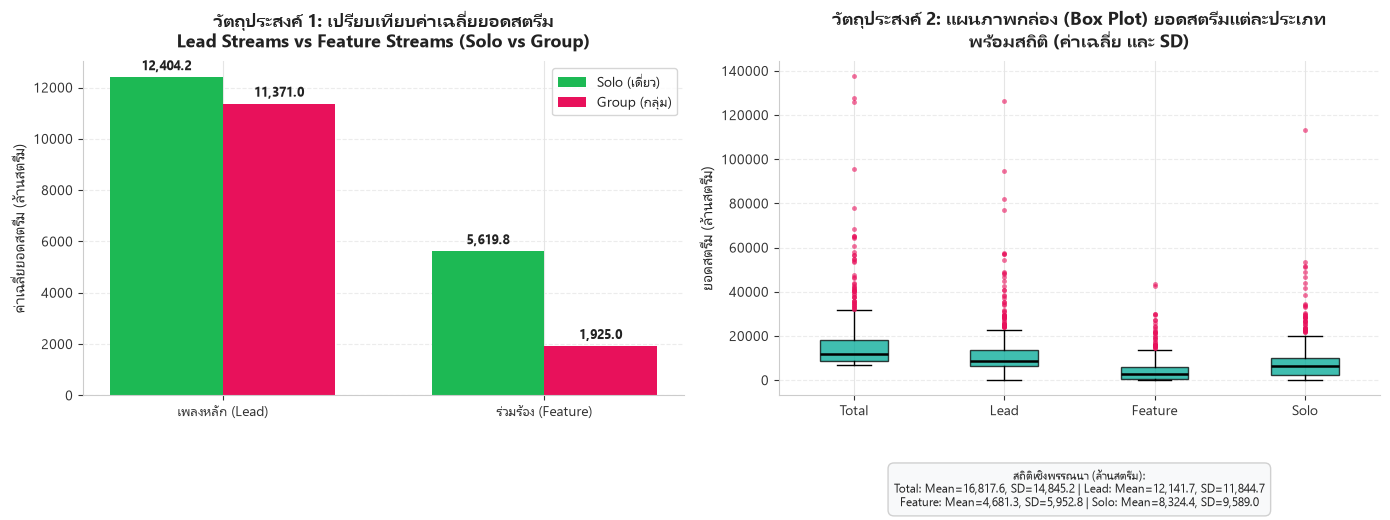

In [ ]:
import os
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ------------------------------------------------------------------
# 1) อ่านข้อมูล Spotify_clean.csv
# ------------------------------------------------------------------
path = r
"C:/Users/dream/Downloads/Spotify_clean.csv"
try:
    df = pd.read_csv(path)
except FileNotFoundError:
    path = "Spotify_clean.csv"
    df = pd.read_csv(path)

df.columns = df.columns.str.strip()

# ทำความสะอาดข้อมูลเบื้องต้น
df = df.drop_duplicates().dropna(subset=["Total Streams (in millions)"])

# ------------------------------------------------------------------
# 2) ตั้งค่าหน้าตากราฟเป็น "ธีมสีขาว (White Theme)" เพื่อให้คมชัด ไม่กลืนกัน
# ------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Leelawadee UI", "Tahoma", "TH Sarabun New", "Thonburi", "Noto Sans Thai", "DejaVu Sans"],
    "axes.unicode_minus": False,
    "figure.facecolor": "#FFFFFF",      # พื้นหลังรูปภาพเป็นสีขาว
    "axes.facecolor": "#FFFFFF",        # พื้นหลังตัวกราฟเป็นสีขาว
    "savefig.facecolor": "#FFFFFF",     # บันทึกเป็นพื้นหลังสีขาว
    "text.color": "#222222",            # ตัวหนังสือสีดำเข้ม
    "axes.labelcolor": "#222222",       # ป้ายชื่อแกนสีดำเข้ม
    "xtick.color": "#333333",           # สเกลแกน X
    "ytick.color": "#333333",           # สเกลแกน Y
    "axes.edgecolor": "#CCCCCC",        # เส้นขอบแกนสีเทาอ่อน
    "grid.color": "#E5E5E5",            # เส้นตารางสีเทาใสอ่านง่าย
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

# ------------------------------------------------------------------
# 3) สร้างกราฟแสดงผลสำหรับวัตถุประสงค์ข้อที่ 1 และ 2
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# ==================================================================
# วัตถุประสงค์ข้อที่ 1: เปรียบเทียบค่าเฉลี่ย Lead Streams และ Feature Streams
# ระหว่าง ศิลปินเดี่ยว (Solo) และ ศิลปินกลุ่ม (Group)
# ==================================================================
solo = df[df["Artist Type"] == "Solo"]
group = df[df["Artist Type"] == "Group"]

metrics = ["Lead Streams (in millions)", "Feature Streams (in millions)"]
x = np.arange(len(metrics))
width = 0.35

mean_solo = [solo[m].mean() for m in metrics]
mean_group = [group[m].mean() for m in metrics]

ax1 = axes[0]
rects1 = ax1.bar(x - width/2, mean_solo, width, label='Solo (เดี่ยว)', color='#1DB954') # เขียว Spotify
rects2 = ax1.bar(x + width/2, mean_group, width, label='Group (กลุ่ม)', color='#E8115B') # ชมพูเข้ม

ax1.set_ylabel('ค่าเฉลี่ยยอดสตรีม (ล้านสตรีม)')
ax1.set_title('วัตถุประสงค์ 1: เปรียบเทียบค่าเฉลี่ยยอดสตรีม\nLead Streams vs Feature Streams (Solo vs Group)', fontweight='bold', pad=10)
ax1.set_xticks(x)
ax1.set_xticklabels(['เพลงหลัก (Lead)', 'ร่วมร้อง (Feature)'])
ax1.legend(frameon=True, facecolor='#FFFFFF', edgecolor='#CCCCCC')
ax1.grid(axis='y', linestyle='--', alpha=0.7)

# ตัวเลขบนตัวแท่งกราฟ
for rect in rects1 + rects2:
    height = rect.get_height()
    ax1.annotate(f'{height:,.1f}',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontsize=9.5, fontweight='bold')

# ==================================================================
# วัตถุประสงค์ข้อที่ 2: แผนภาพกล่อง (Box Plot) แสดงสัดส่วนการกระจาย
# พร้อมแสดงค่าเฉลี่ย (Mean) และส่วนเบี่ยงเบนมาตรฐาน (SD)
# ==================================================================
stream_cols = [
    "Total Streams (in millions)",
    "Lead Streams (in millions)",
    "Feature Streams (in millions)",
    "Solo Streams (in millions)"
]
box_labels = ["Total", "Lead", "Feature", "Solo"]
data_to_plot = [df[col].dropna() for col in stream_cols]

ax2 = axes[1]
bp = ax2.boxplot(data_to_plot, patch_artist=True, tick_labels=box_labels,
                 flierprops=dict(marker='o', markersize=3.5, alpha=0.6, markerfacecolor='#E8115B', markeredgecolor='none'),
                 medianprops=dict(color='#000000', linewidth=1.8))

# ตกแต่งสีกล่องเป็นโทนฟ้าอมเขียวสว่าง
for box in bp['boxes']:
    box.set_facecolor('#00A896')
    box.set_alpha(0.75)

ax2.set_ylabel('ยอดสตรีม (ล้านสตรีม)')
ax2.set_title('วัตถุประสงค์ 2: แผนภาพกล่อง (Box Plot) ยอดสตรีมแต่ละประเภท\nพร้อมสถิติ (ค่าเฉลี่ย และ SD)', fontweight='bold', pad=10)
ax2.grid(axis='y', linestyle='--', alpha=0.7)

# คำนวณและแสดงค่าทางสถิติ (Mean & SD) ด้านล่างกราฟ Box Plot
stats_text = []
for col_name, short_label in zip(stream_cols, box_labels):
    m = df[col_name].mean()
    sd = df[col_name].std()
    stats_text.append(f"{short_label}: Mean={m:,.1f}, SD={sd:,.1f}")

text_str = "สถิติเชิงพรรณนา (ล้านสตรีม):\n" + " | ".join(stats_text[:2]) + "\n" + " | ".join(stats_text[2:])
ax2.text(0.5, -0.22, text_str, transform=ax2.transAxes, ha='center', va='top',
         fontsize=8.5, bbox=dict(boxstyle='round,pad=0.5', facecolor='#F8F9FA', edgecolor='#CCCCCC', alpha=0.9))

plt.tight_layout()

# แสดงรูปภาพกราฟออกมาบนหน้าจอ
plt.show()

=== ตารางย่อยสรุปผล (Sub-table) ===
Artist Type  จํานวนศิลปิน ยอดสตรีมรวมเฉลี่ย ยอดเพลงหลักเฉลี่ย ยอดร่วมร้องเฉลี่ย
      Group           127         13,290.13         11,370.98          1,924.98
       Solo           373         18,018.65         12,404.16          5,619.76


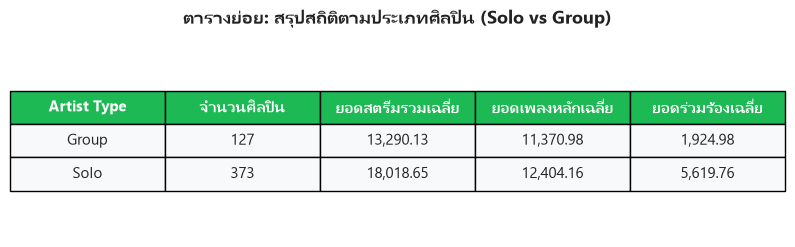

In [18]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------
# 1) อ่านข้อมูลจากไฟล์ Spotify_clean.csv
# ------------------------------------------------------------------
path = r"C:/Users/dream/Downloads/Spotify_clean.csv"
df = pd.read_csv(path)
df.columns = df.columns.str.strip()

# ------------------------------------------------------------------
# 2) สร้าง "ตารางย่อย" (Sub-table) สรุปค่าเฉลี่ยตามประเภทศิลปิน
# ------------------------------------------------------------------
sub_table = df.groupby("Artist Type").agg(
    จำนวนศิลปิน=("Artist Name", "count"),
    ยอดสตรีมรวมเฉลี่ย=("Total Streams (in millions)", "mean"),
    ยอดเพลงหลักเฉลี่ย=("Lead Streams (in millions)", "mean"),
    ยอดร่วมร้องเฉลี่ย=("Feature Streams (in millions)", "mean")
).reset_index()

# จัดรูปแบบตัวเลขให้สวยงาม (ทศนิยม 2 ตำแหน่ง พร้อมใส่เครื่องหมายคอมม่า)
for col in ["ยอดสตรีมรวมเฉลี่ย", "ยอดเพลงหลักเฉลี่ย", "ยอดร่วมร้องเฉลี่ย"]:
    sub_table[col] = sub_table[col].apply(lambda x: f"{x:,.2f}")

print("=== ตารางย่อยสรุปผล (Sub-table) ===")
print(sub_table.to_string(index=False))

# ------------------------------------------------------------------
# 3) บันทึกตารางย่อยเป็นไฟล์ CSV และแปลงเป็นรูปภาพตาราง
# ------------------------------------------------------------------
os.makedirs("charts", exist_ok=True)
sub_table.to_csv("charts/sub_table_summary.csv", index=False, encoding="utf-8-sig")

# สร้างรูปภาพตารางสวยๆ แสดงผลใน Notebook
fig, ax = plt.subplots(figsize=(10, 2.5))
ax.axis("off")

table = ax.table(
    cellText=sub_table.values,
    colLabels=sub_table.columns,
    loc="center",
    cellLoc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 2) # ปรับขนาดความสูงของแถว

# ตกแต่งสีหัวตารางให้เป็นโทนเขียว-ขาวสะอาดตา อ่านง่าย
for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_facecolor("#1DB954") # สีเขียว Spotify
        cell.get_text().set_color("#FFFFFF")
        cell.get_text().set_weight("bold")
    else:
        cell.set_facecolor("#F8F9FA")
        cell.get_text().set_color("#222222")

plt.title("ตารางย่อย: สรุปสถิติตามประเภทศิลปิน (Solo vs Group)", fontsize=13, fontweight="bold", pad=15)

# บันทึกรูปตารางเก็บไว้ในโฟลเดอร์ charts
plt.savefig("charts/sub_table_image.png", dpi=200, bbox_inches="tight")

# แสดงผลรูปตารางออกมาบนหน้าจอทันที
plt.show()

In [20]:
import pandas as pd

# 1) อ่านไฟล์ CSV (ดึงจากโฟลเดอร์ปัจจุบันหรือระบุพาธตามที่ใช้งาน)
path = "Spotify_clean.csv" # หรือใส่ r"C:\Users\dream\Downloads\Spotify_clean.csv"
df = pd.read_csv("C:/Users/dream/Downloads/Spotify_clean.csv")
df.columns = df.columns.str.strip()

# 2) เลือกแสดงเฉพาะคอลัมน์สำคัญๆ หรือดู 10 แถวแรก
sample_df = df.head(10)[["Artist Name", "Artist Type", "Debut Year", "Primary Genre", "Total Streams (in millions)", "Lead Streams (in millions)"]]

print("=== ตารางตัวอย่างข้อมูลศิลปิน 10 แถวแรก ===")
display(sample_df)  # สำหรับรันใน Jupyter Notebook จะแสดงเป็นตารางสวยๆ

=== ตารางตัวอย่างข้อมูลศิลปิน 10 แถวแรก ===


,Artist Name,Artist Type,Debut Year,Primary Genre,Total Streams (in millions),Lead Streams (in millions)
0,Drake,Solo,2006,Hip-Hop,137492.1,94851.1
1,Taylor Swift,Solo,2006,Pop,127861.0,126177.3
2,Bad Bunny,Solo,2013,Reggaeton,125899.8,82189.3
3,The Weeknd,Solo,2009,R&B,95703.2,77189.4
4,Justin Bieber,Solo,2009,Pop,78104.4,48316.2
5,Ariana Grande,Solo,2013,Pop,68298.9,57097.5
6,Travis Scott,Solo,2013,Hip-Hop,65349.7,35338.7
7,Kanye West,Solo,2004,Hip-Hop,65142.9,46558.4
8,Ed Sheeran,Solo,2011,Pop,64656.9,57704.0
9,Eminem,Solo,1996,Hip-Hop,64549.0,54466.8


In [23]:
import pandas as pd

# 1) อ่านไฟล์ข้อมูล Spotify_clean.csv
path = r"C:/Users/dream/Downloads/Spotify_clean.csv"
try:
    df = pd.read_csv(path)
except FileNotFoundError:
    df = pd.read_csv("Spotify_clean.csv")

df.columns = df.columns.str.strip()

# 2) เลือกคอลัมน์ยอดสตรีมที่ต้องการคำนวณ
stream_cols = [
    "Total Streams (in millions)",
    "Lead Streams (in millions)",
    "Feature Streams (in millions)",
    "Solo Streams (in millions)"
]

# 3) คำนวณค่าสถิติเชิงพรรณนาแบบถูกต้อง (ใช้ฟังก์ชัน list พร้อมเปลี่ยนชื่อคอลัมน์ทีหลัง)
stats_df = df[stream_cols].agg(['mean', 'median', 'std', 'min', 'max']).T
stats_df.columns = ['Mean', 'Median', 'SD', 'Min', 'Max']

# เปลี่ยนชื่อแถวให้อ่านง่ายขึ้น
stats_df.index = ["Total Streams", "Lead Streams", "Feature Streams", "Solo Streams"]

# จัดรูปแบบตัวเลขให้ใส่คอมม่าและทศนิยม 2 ตำแหน่ง
for col in stats_df.columns:
    stats_df[col] = stats_df[col].apply(lambda x: f"{x:,.2f}")

print("=== ตารางสถิติเชิงพรรณนายอดสตรีม (หน่วย: ล้านสตรีม) ===")
display(stats_df) # แสดงผลเป็นตารางสวยงามใน Jupyter Notebook

=== ตารางสถิติเชิงพรรณนายอดสตรีม (หน่วย: ล้านสตรีม) ===


,Mean,Median,SD,Min,Max
Total Streams,"16,817.61","11,923.25","14,845.20","6,972.00","137,492.10"
Lead Streams,"12,141.73","8,716.35","11,844.68",0.00,"126,177.30"
Feature Streams,"4,681.29","3,005.60","5,952.83",0.00,"43,710.50"
Solo Streams,"8,324.40","6,472.95","9,589.01",0.00,"113,421.50"


=== ตารางสถิติเชิงพรรณนายอดสตรีม (Mean, Median, SD) ===


,Mean,Median,SD
Total Streams,"16,817.61","11,923.25","14,845.20"
Lead Streams,"12,141.73","8,716.35","11,844.68"
Feature Streams,"4,681.29","3,005.60","5,952.83"
Solo Streams,"8,324.40","6,472.95","9,589.01"


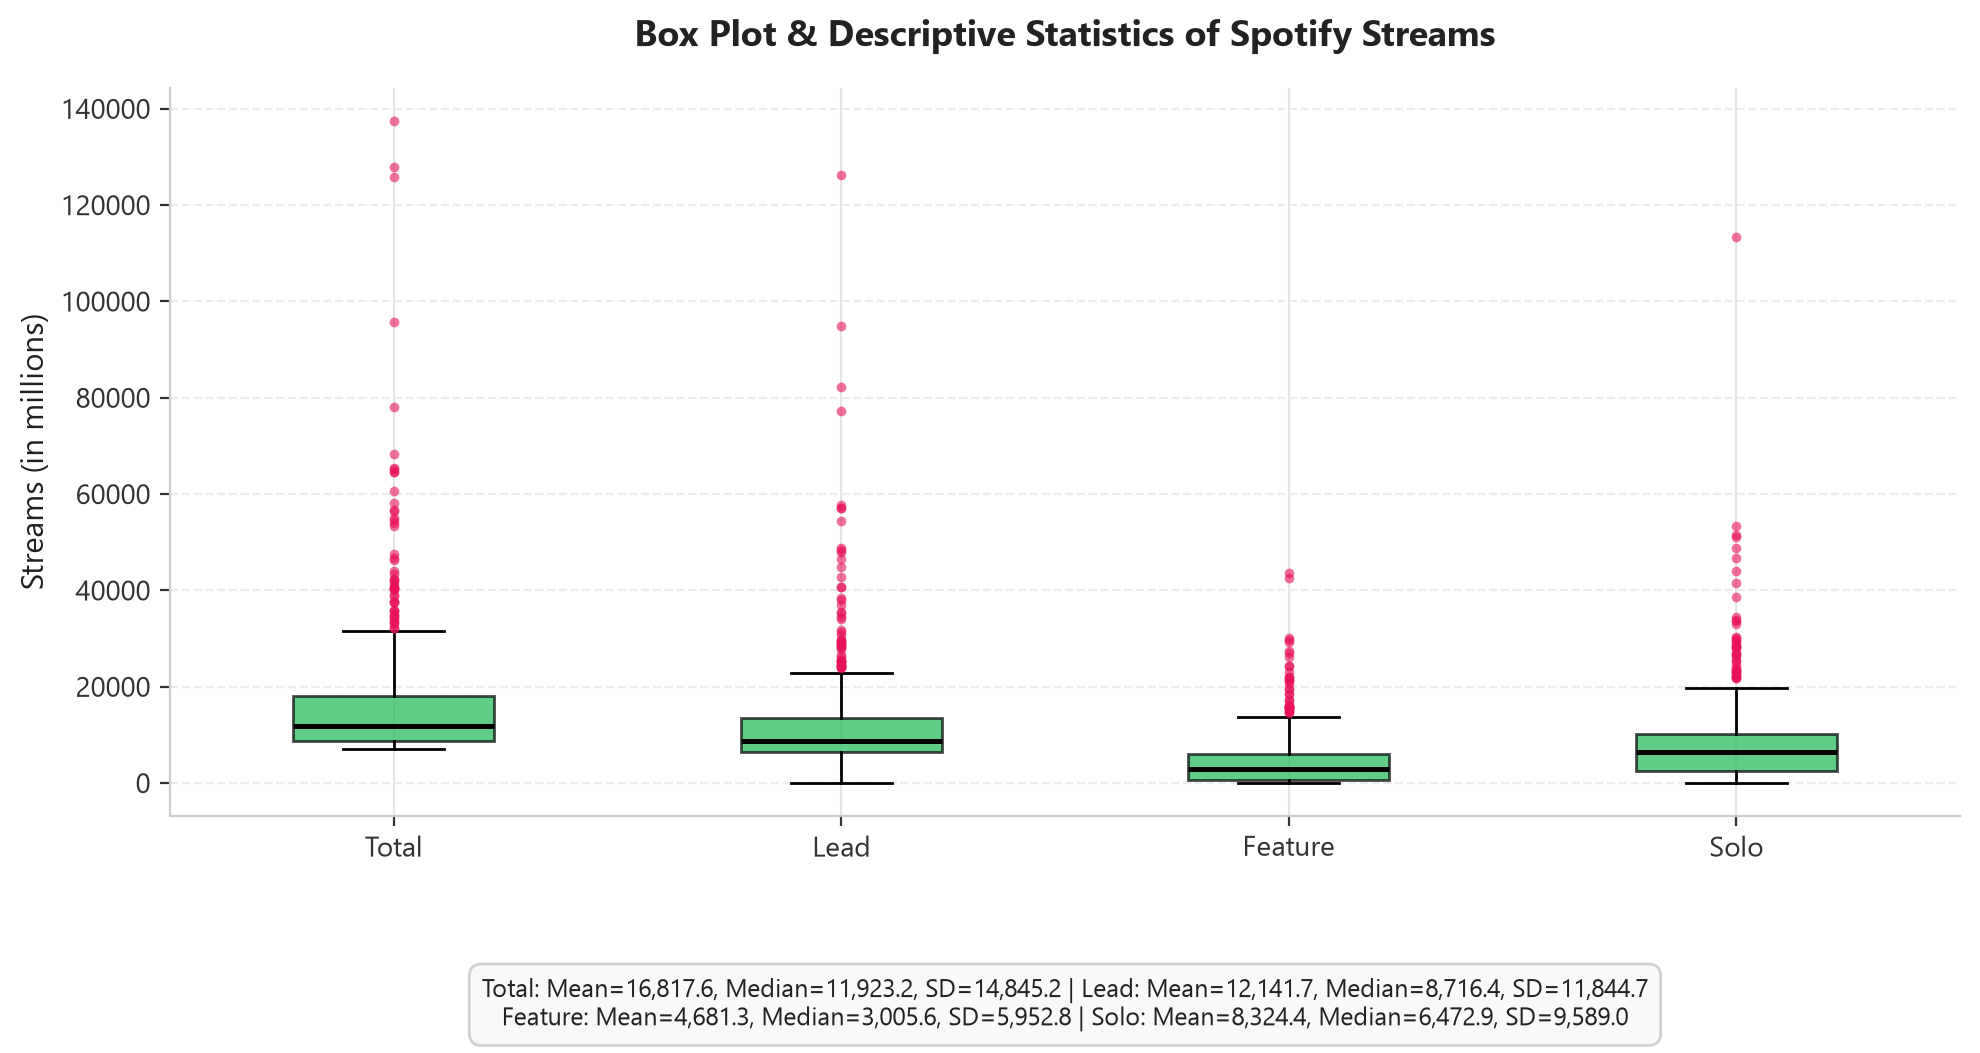

In [30]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------------
# 1) อ่านไฟล์ข้อมูล Spotify_clean.csv
# ------------------------------------------------------------------
path = r"C:/Users/dream/Downloads/Spotify_clean.csv"
try:
  df = pd.read_csv(path)
except FileNotFoundError:
  df = pd.read_csv("Spotify_clean.csv")

df.columns = df.columns.str.strip()

# ------------------------------------------------------------------
# 2) คอลัมน์ยอดสตรีมทั้ง 4 ประเภท
# ------------------------------------------------------------------
stream_cols = [
    "Total Streams (in millions)",
    "Lead Streams (in millions)",
    "Feature Streams (in millions)",
    "Solo Streams (in millions)",
]
box_labels = ["Total", "Lead", "Feature", "Solo"]

# ------------------------------------------------------------------
# 3) สถิติเชิงพรรณนา (คำนวณเฉพาะ Mean, Median, SD - ไม่เอา Min และ Max)
# ------------------------------------------------------------------
stats_df = df[stream_cols].agg(["mean", "median", "std"]).T
stats_df.columns = ["Mean", "Median", "SD"]
stats_df.index = [
    "Total Streams",
    "Lead Streams",
    "Feature Streams",
    "Solo Streams",
]

# จัดรูปแบบตัวเลขให้ใส่คอมม่าและทศนิยม 2 ตำแหน่ง
stats_display = stats_df.copy()
for col in stats_display.columns:
  stats_display[col] = stats_display[col].apply(lambda x: f"{x:,.2f}")

print("=== ตารางสถิติเชิงพรรณนายอดสตรีม (Mean, Median, SD) ===")
display(stats_display)

# ------------------------------------------------------------------
# 4) สร้างแผนภาพกล่อง (Box Plot) พร้อมกล่องสรุปค่าสถิติ
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=200)

data_to_plot = [df[col].dropna() for col in stream_cols]
bp = ax.boxplot(
    data_to_plot,
    patch_artist=True,
    tick_labels=box_labels,  # <--- แก้ไขใช้ tick_labels ให้รองรับเวอร์ชันปัจจุบัน
    flierprops=dict(
        marker="o",
        markersize=3.5,
        alpha=0.6,
        markerfacecolor="#E8115B",
        markeredgecolor="none",
    ),
    medianprops=dict(color="#000000", linewidth=1.8),
)

# ตกแต่งสีกล่องกราฟ (สีเขียว Spotify)
for box in bp["boxes"]:
  box.set_facecolor("#1DB954")
  box.set_alpha(0.7)

ax.set_ylabel("Streams (in millions)")
ax.set_title(
    "Box Plot & Descriptive Statistics of Spotify Streams",
    fontweight="bold",
    pad=15,
)
ax.grid(axis="y", linestyle="--", alpha=0.7)

# สรุปข้อความสถิติเชิงพรรณนาไว้ใต้กราฟ Box Plot
stats_text = []
for col_name, short_label in zip(stream_cols, box_labels):
  m = df[col_name].mean()
  med = df[col_name].median()
  sd = df[col_name].std()
  stats_text.append(
      f"{short_label}: Mean={m:,.1f}, Median={med:,.1f}, SD={sd:,.1f}"
  )

text_str = " | ".join(stats_text[:2]) + "\n" + " | ".join(stats_text[2:])
ax.text(
    0.5,
    -0.22,
    text_str,
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=9,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="#F8F9FA",
        edgecolor="#CCCCCC",
        alpha=0.9,
    ),
)

plt.tight_layout()

# ------------------------------------------------------------------
# 5) บันทึกรูปภาพลงโฟลเดอร์ charts และแสดงผล
# ------------------------------------------------------------------
os.makedirs("charts", exist_ok=True)
plt.savefig("charts/boxplot_with_selected_stats.png", bbox_inches="tight")

plt.show()

=== Descriptive Statistics Table ===


,Mean,Median,SD
Total Streams,"16,817.61","11,923.25","14,845.20"
Lead Streams,"12,141.73","8,716.35","11,844.68"
Feature Streams,"4,681.29","3,005.60","5,952.83"
Solo Streams,"8,324.40","6,472.95","9,589.01"


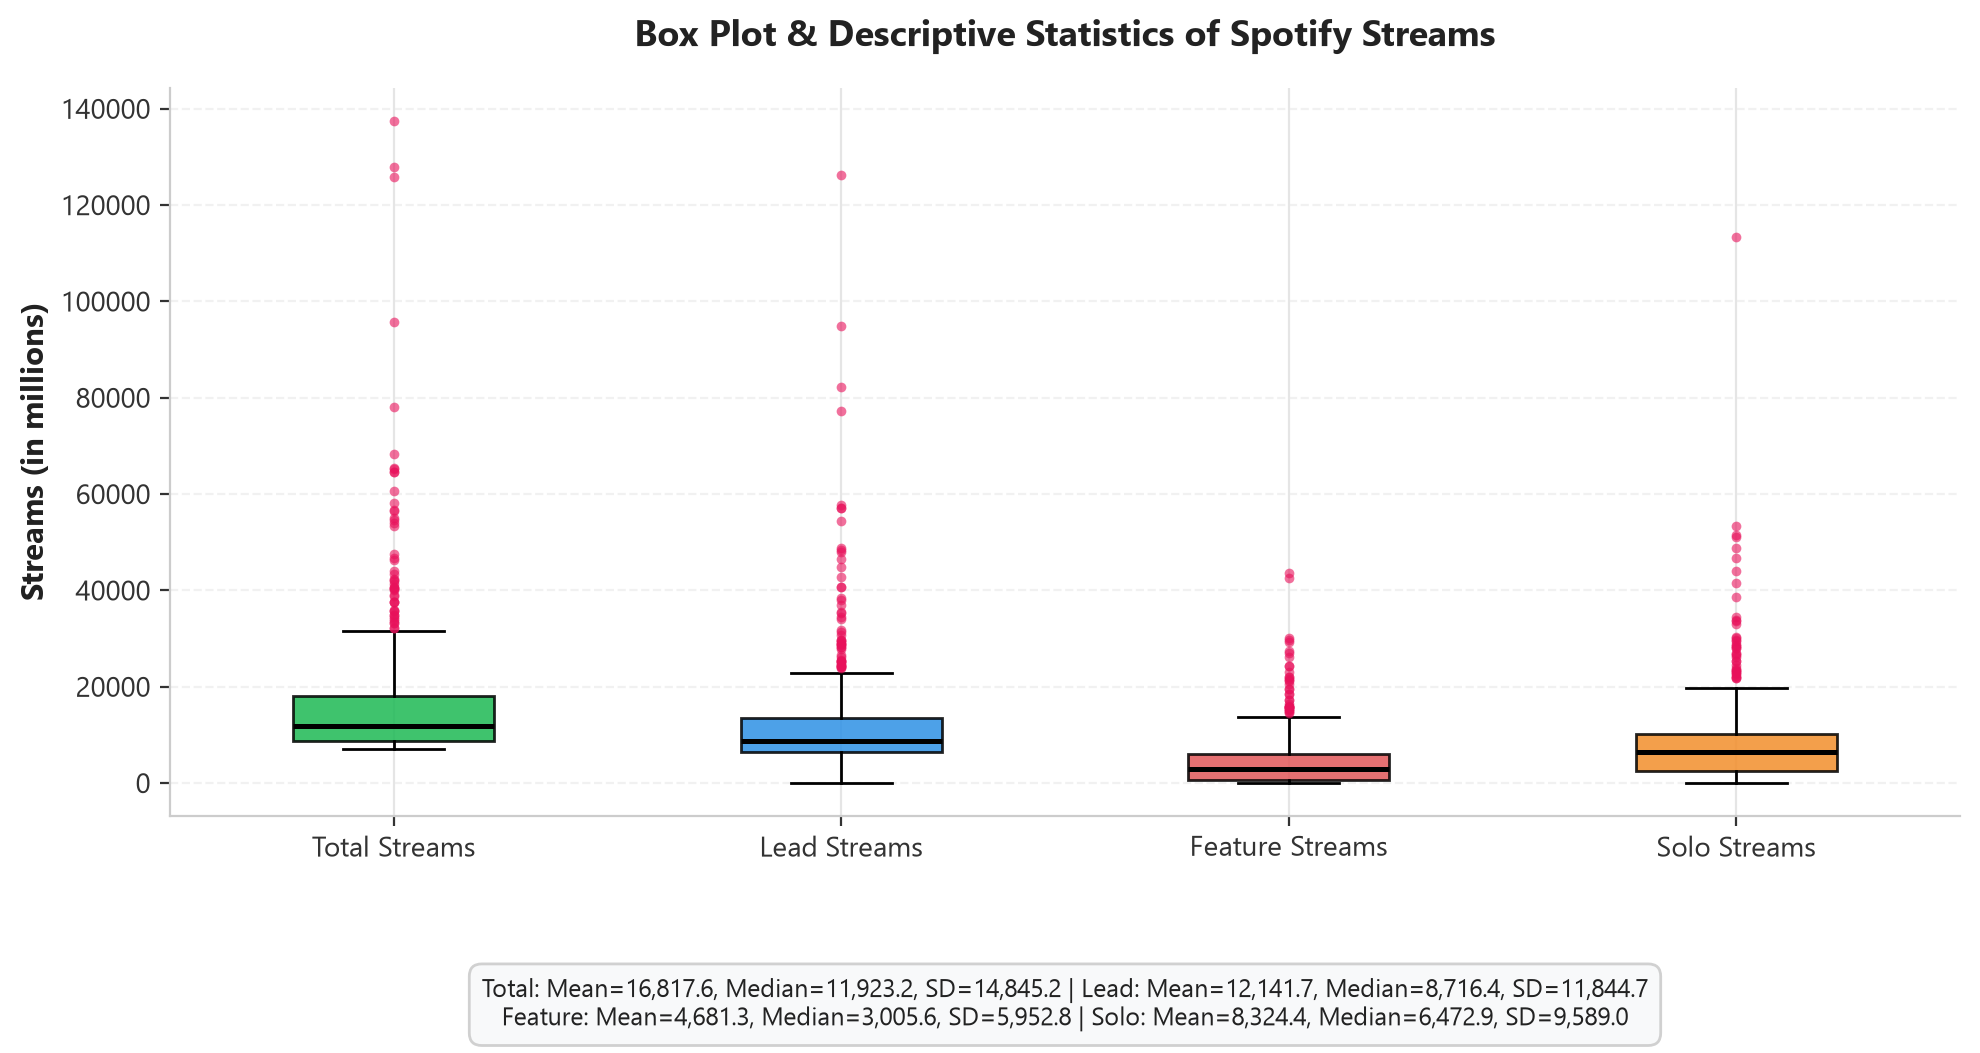

In [33]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------------
# 1) อ่านข้อมูลจากไฟล์ Spotify_clean.csv
# ------------------------------------------------------------------
path = r"C:/Users/dream/Downloads/Spotify_clean.csv"
try:
  df = pd.read_csv(path)
except FileNotFoundError:
  df = pd.read_csv("Spotify_clean.csv")

df.columns = df.columns.str.strip()

# ------------------------------------------------------------------
# 2) กำหนดตัวแปรและคอลัมน์ที่ต้องการวิเคราะห์
# ------------------------------------------------------------------
stream_cols = [
    "Total Streams (in millions)",
    "Lead Streams (in millions)",
    "Feature Streams (in millions)",
    "Solo Streams (in millions)",
]
box_labels = ["Total Streams", "Lead Streams", "Feature Streams", "Solo Streams"]

# ------------------------------------------------------------------
# 3) คำนวณตารางสถิติเชิงพรรณนา (Mean, Median, SD)
# ------------------------------------------------------------------
stats_df = df[stream_cols].agg(["mean", "median", "std"]).T
stats_df.columns = ["Mean", "Median", "SD"]
stats_df.index = box_labels

# จัดรูปแบบตารางสำหรับแสดงผล
stats_display = stats_df.copy()
for col in stats_display.columns:
  stats_display[col] = stats_display[col].apply(lambda x: f"{x:,.2f}")

print("=== Descriptive Statistics Table ===")
display(stats_display)

# ------------------------------------------------------------------
# 4) สร้างแผนภาพกล่องแบบหลากสี (Multi-Color Box Plot)
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=200)

data_to_plot = [df[col].dropna() for col in stream_cols]

# สร้าง Box Plot (ใช้ tick_labels ตามเวอร์ชันปัจจุบันของเครื่อง)
bp = ax.boxplot(
    data_to_plot,
    patch_artist=True,
    tick_labels=box_labels,
    flierprops=dict(
        marker="o",
        markersize=3.5,
        alpha=0.6,
        markerfacecolor="#E8115B",
        markeredgecolor="none",
    ),
    medianprops=dict(color="#000000", linewidth=1.8),
)

# กำหนดสีทางการแยกตามประเภทตัวแปร (Total, Lead, Feature, Solo)
official_colors = [
    "#1DB954",  # เขียว (Total)
    "#2E91E5",  # ฟ้า (Lead)
    "#E15759",  # แดงอิฐ (Feature)
    "#F28E2B",  # ส้ม (Solo)
]

for patch, color in zip(bp["boxes"], official_colors):
  patch.set_facecolor(color)
  patch.set_alpha(0.85)

# ตั้งค่าแกนและชื่อเรื่อง
ax.set_ylabel("Streams (in millions)", fontsize=11, fontweight="bold")
ax.set_title(
    "Box Plot & Descriptive Statistics of Spotify Streams",
    fontweight="bold",
    fontsize=13,
    pad=15,
)
ax.grid(axis="y", linestyle="--", alpha=0.5)

# คำนวณค่าสถิติแปะเป็นกล่องข้อความไว้ใต้กราฟ
stats_text = []
for col_name, short_label in zip(stream_cols, ["Total", "Lead", "Feature", "Solo"]):
  m = df[col_name].mean()
  med = df[col_name].median()
  sd = df[col_name].std()
  stats_text.append(
      f"{short_label}: Mean={m:,.1f}, Median={med:,.1f}, SD={sd:,.1f}"
  )

text_str = " | ".join(stats_text[:2]) + "\n" + " | ".join(stats_text[2:])
ax.text(
    0.5,
    -0.22,
    text_str,
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=9,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="#F8F9FA",
        edgecolor="#CCCCCC",
        alpha=0.9,
    ),
)

plt.tight_layout()

# ------------------------------------------------------------------
# 5) บันทึกและแสดงผล
# ------------------------------------------------------------------
os.makedirs("charts", exist_ok=True)
plt.savefig("charts/multicolor_boxplot_official.png", bbox_inches="tight")

plt.show()

Solo Artist  : Mean = 12,404.16 M, SD = 12,881.10 M (n = 373)
Group Artist : Mean = 11,370.98 M, SD = 8,059.03 M (n = 127)


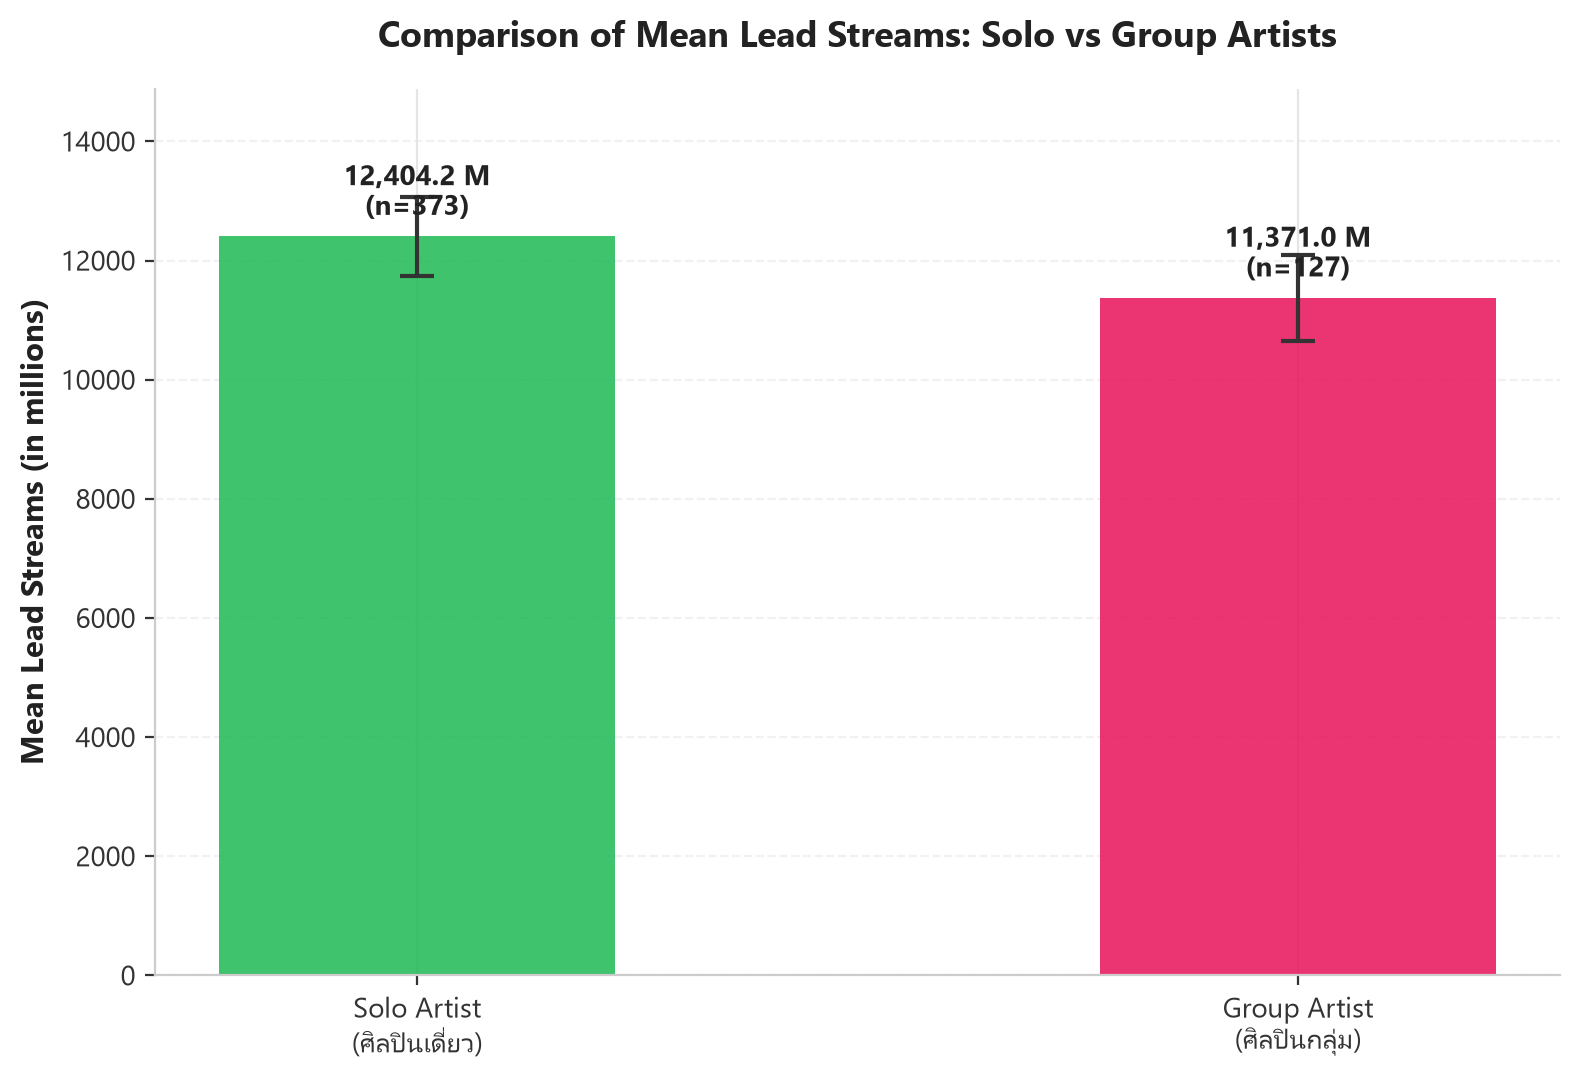

In [34]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ------------------------------------------------------------------
# 1) อ่านข้อมูลจากไฟล์ Spotify_clean.csv
# ------------------------------------------------------------------
path = r"C:/Users/dream/Downloads/Spotify_clean.csv"
try:
  df = pd.read_csv(path)
except FileNotFoundError:
  df = pd.read_csv("Spotify_clean.csv")

df.columns = df.columns.str.strip()

# ------------------------------------------------------------------
# 2) แยกข้อมูลตามประเภทศิลปิน (Solo vs Group)
# ------------------------------------------------------------------
solo_lead = df[df["Artist Type"] == "Solo"]["Lead Streams (in millions)"]
group_lead = df[df["Artist Type"] == "Group"]["Lead Streams (in millions)"]

# คำนวณค่าเฉลี่ย (Mean) และ Standard Error (SE)
means = [solo_lead.mean(), group_lead.mean()]
sems = [
    solo_lead.std() / np.sqrt(len(solo_lead)),
    group_lead.std() / np.sqrt(len(group_lead)),
]
categories = ["Solo Artist\n(ศิลปินเดี่ยว)", "Group Artist\n(ศิลปินกลุ่ม)"]
counts = [len(solo_lead), len(group_lead)]

# แสดงสรุปผลทางสถิติบนคอนโซล
print(
    f"Solo Artist  : Mean = {means[0]:,.2f} M, SD = {solo_lead.std():,.2f} M (n"
    f" = {counts[0]})"
)
print(
    f"Group Artist : Mean = {means[1]:,.2f} M, SD = {group_lead.std():,.2f} M (n"
    f" = {counts[1]})"
)

# ------------------------------------------------------------------
# 3) สร้างกราฟแท่งเปรียบเทียบค่าเฉลี่ย (Bar Chart)
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5.5), dpi=200)

# กำหนดสี (เขียว Spotify สำหรับ Solo, ชมพูเข้มสำหรับ Group)
colors = ["#1DB954", "#E8115B"]

bars = ax.bar(
    categories,
    means,
    yerr=sems,
    capsize=6,
    color=colors,
    alpha=0.85,
    width=0.45,
    error_kw=dict(lw=1.5, capthick=1.5, ecolor="#333333"),
)

# ตกแต่งแกนและชื่อเรื่อง
ax.set_ylabel(
    "Mean Lead Streams (in millions)", fontsize=11, fontweight="bold"
)
ax.set_title(
    "Comparison of Mean Lead Streams: Solo vs Group Artists",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
ax.set_ylim(0, max(means) * 1.2)  # เผื่อพื้นที่ด้านบนสำหรับตัวเลข
ax.grid(axis="y", linestyle="--", alpha=0.5)

# แสดงตัวเลขค่าเฉลี่ยกำกับบนตัวแท่งกราฟ
for bar, mean_val, count in zip(bars, means, counts):
  height = bar.get_height()
  ax.annotate(
      f"{mean_val:,.1f} M\n(n={count})",
      xy=(bar.get_x() + bar.get_width() / 2, height),
      xytext=(0, 5),
      textcoords="offset points",
      ha="center",
      va="bottom",
      fontsize=10,
      fontweight="bold",
  )

plt.tight_layout()

# ------------------------------------------------------------------
# 4) บันทึกรูปภาพลงโฟลเดอร์ charts และแสดงผล
# ------------------------------------------------------------------
os.makedirs("charts", exist_ok=True)
plt.savefig("charts/solo_vs_group_lead_streams.png", bbox_inches="tight")

plt.show()

Lead Streams Mean    : 12,141.73 ล้านสตรีม
Feature Streams Mean : 4,681.29 ล้านสตรีม
Pearson Correlation (r)  : 0.317
Spearman Correlation (r_s): -0.109


C:\Users\dream\AppData\Local\Temp\ipykernel_19548\884069635.py:104: UserWarning: Glyph 8347 (\N{LATIN SUBSCRIPT SMALL LETTER S}) missing from font(s) Leelawadee UI.
  plt.tight_layout()
C:\Users\dream\AppData\Local\Temp\ipykernel_19548\884069635.py:110: UserWarning: Glyph 8347 (\N{LATIN SUBSCRIPT SMALL LETTER S}) missing from font(s) Leelawadee UI.
  plt.savefig("charts/lead_vs_feature_scatter.png", bbox_inches="tight")
C:\Users\dream\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8347 (\N{LATIN SUBSCRIPT SMALL LETTER S}) missing from font(s) Leelawadee UI.
  fig.canvas.print_figure(bytes_io, **kw)


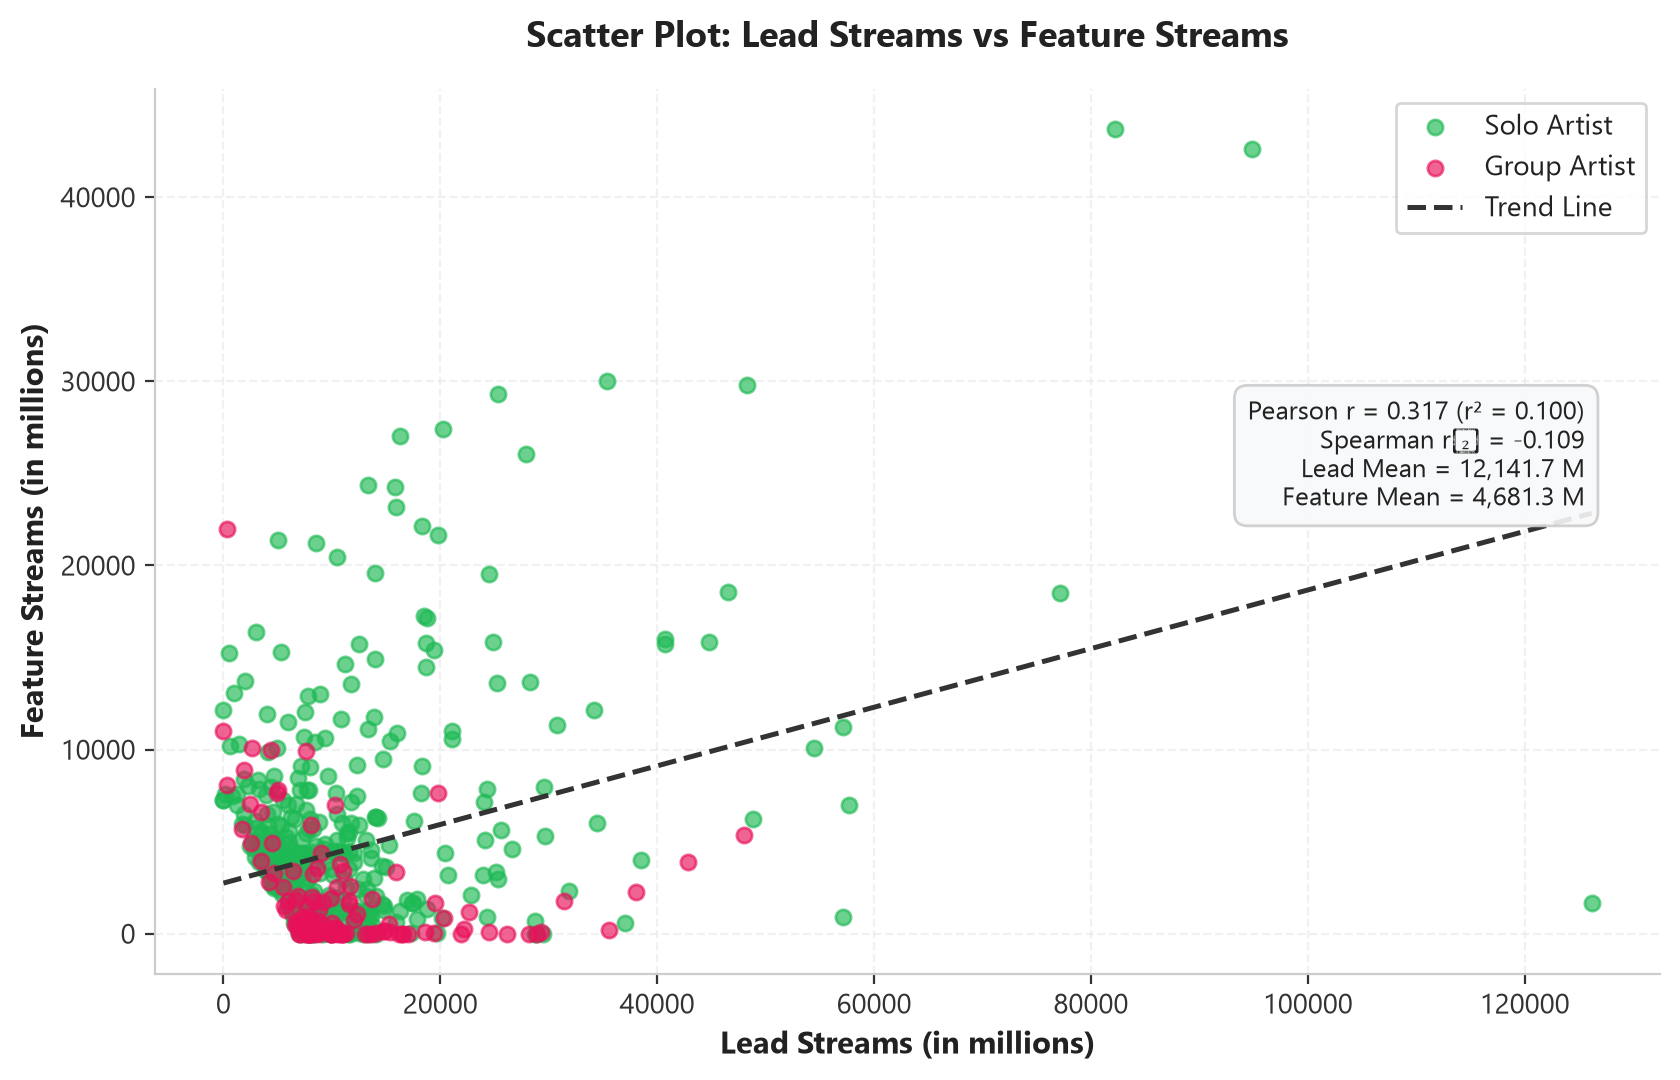

In [35]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ------------------------------------------------------------------
# 1) อ่านข้อมูลจากไฟล์ Spotify_clean.csv
# ------------------------------------------------------------------
path = r"C:/Users/dream/Downloads/Spotify_clean.csv"
try:
  df = pd.read_csv(path)
except FileNotFoundError:
  df = pd.read_csv("Spotify_clean.csv")

df.columns = df.columns.str.strip()

# ------------------------------------------------------------------
# 2) ดึงข้อมูล Lead Streams และ Feature Streams
# ------------------------------------------------------------------
lead = df["Lead Streams (in millions)"]
feat = df["Feature Streams (in millions)"]

# คำนวณค่าสัมประสิทธิ์สหสัมพันธ์ (Correlation)
r_p = lead.corr(feat)  # Pearson
r_s = lead.corr(feat, method="spearman")  # Spearman

print(f"Lead Streams Mean    : {lead.mean():,.2f} ล้านสตรีม")
print(f"Feature Streams Mean : {feat.mean():,.2f} ล้านสตรีม")
print(f"Pearson Correlation (r)  : {r_p:.3f}")
print(f"Spearman Correlation (r_s): {r_s:.3f}")

# ------------------------------------------------------------------
# 3) สร้างกราฟการกระจาย (Scatter Plot) พร้อมเส้นแนวโน้ม
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8.5, 5.5), dpi=200)

solo = df[df["Artist Type"] == "Solo"]
group = df[df["Artist Type"] == "Group"]

# พล็อตจุดกระจายแยกตามศิลปินเดี่ยว (เขียว) และกลุ่ม (ชมพู)
ax.scatter(
    solo["Lead Streams (in millions)"],
    solo["Feature Streams (in millions)"],
    s=30,
    alpha=0.65,
    color="#1DB954",
    label="Solo Artist",
)
ax.scatter(
    group["Lead Streams (in millions)"],
    group["Feature Streams (in millions)"],
    s=30,
    alpha=0.65,
    color="#E8115B",
    label="Group Artist",
)

# สร้างเส้นแนวโน้ม (Trend Line)
m, b = np.polyfit(lead, feat, 1)
xs = np.linspace(lead.min(), lead.max(), 100)
ax.plot(
    xs,
    m * xs + b,
    color="#333333",
    linestyle="--",
    linewidth=1.8,
    label="Trend Line",
)

# ตกแต่งแกนและชื่อเรื่อง
ax.set_xlabel("Lead Streams (in millions)", fontsize=11, fontweight="bold")
ax.set_ylabel("Feature Streams (in millions)", fontsize=11, fontweight="bold")
ax.set_title(
    "Scatter Plot: Lead Streams vs Feature Streams",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper right", frameon=True, facecolor="#FFFFFF", edgecolor="#CCCCCC")

# แสดงกล่องสรุปค่าสัมประสิทธิ์สหสัมพันธ์และค่าเฉลี่ย
stats_box = (
    f"Pearson r = {r_p:.3f} (r² = {r_p**2:.3f})\nSpearman rₛ ="
    f" {r_s:.3f}\nLead Mean = {lead.mean():,.1f} M\nFeature Mean ="
    f" {feat.mean():,.1f} M"
)
ax.text(
    0.95,
    0.65,
    stats_box,
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=9.5,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="#F8F9FA",
        edgecolor="#CCCCCC",
        alpha=0.9,
    ),
)

plt.tight_layout()

# ------------------------------------------------------------------
# 4) บันทึกรูปภาพลงโฟลเดอร์ charts และแสดงผล
# ------------------------------------------------------------------
os.makedirs("charts", exist_ok=True)
plt.savefig("charts/lead_vs_feature_scatter.png", bbox_inches="tight")

plt.show()

--- ตารางสรุปรายปี (ตัวอย่างบางปี) ---
 Debut Year  Artist_Count  Mean_Total_Streams
       2009            24        21857.595833
       2010            28        16525.896429
       2011            22        23451.354545
       2012            27        16704.044444
       2013            24        25945.091667
       2014            32        16404.862500
       2015            29        17032.341379
       2016            17        14894.035294
       2017            28        12267.210714
       2018            14        12878.792857
       2019            11        12142.009091
       2020             6        13328.400000
       2021             4        13631.425000
       2022             2        10943.100000
       2023             2        12010.300000

Pearson Correlation (r): 0.4719


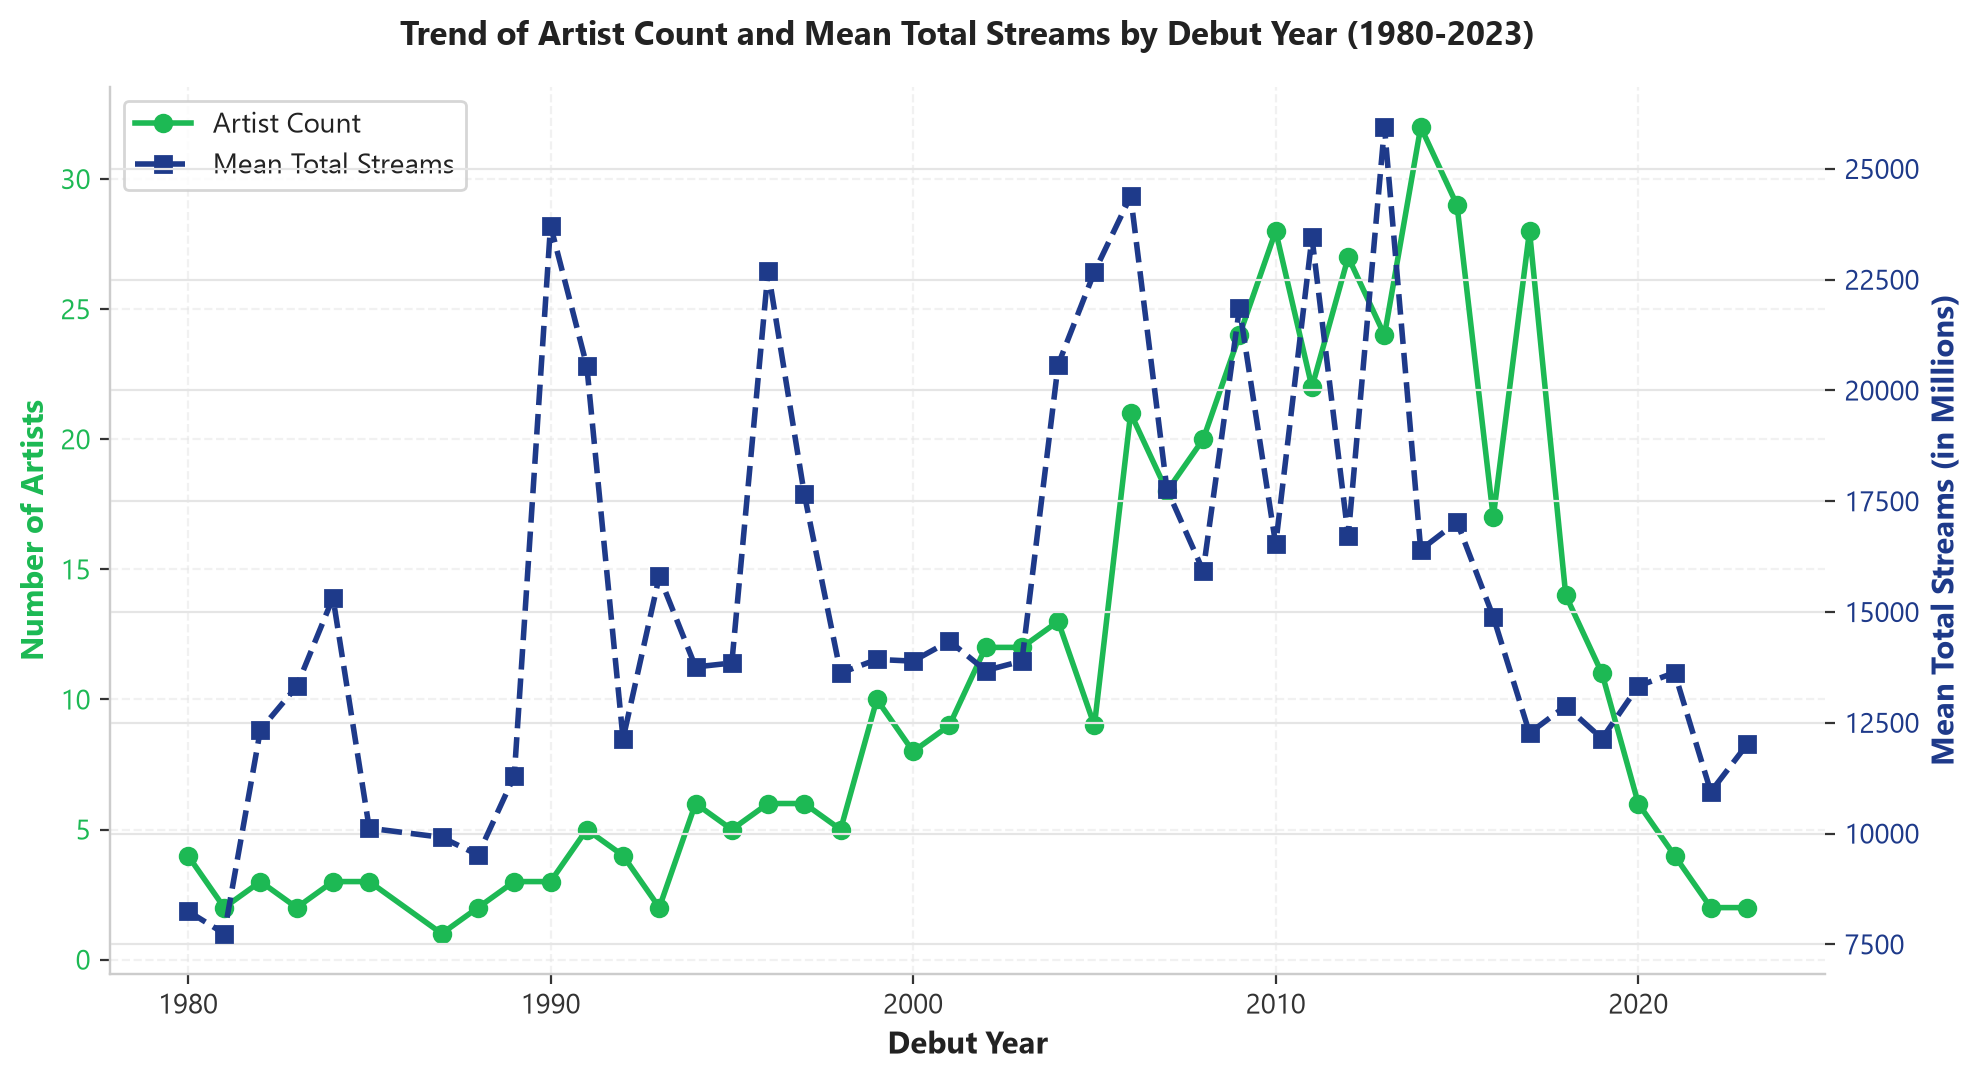

In [36]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------------
# 1) อ่านข้อมูลและเตรียมข้อมูล
# ------------------------------------------------------------------
path = r"C:/Users/dream/Downloads/Spotify_clean.csv"
try:
  df = pd.read_csv(path)
except FileNotFoundError:
  df = pd.read_csv("Spotify_clean.csv")

df.columns = df.columns.str.strip()

# ------------------------------------------------------------------
# 2) สรุปข้อมูลรายปี (จำนวนศิลปิน & ค่าเฉลี่ยยอดสตรีมมิ่ง)
# ------------------------------------------------------------------
yearly_summary = (
    df.groupby("Debut Year")
    .agg(
        Artist_Count=("Artist Name", "count"),
        Mean_Total_Streams=("Total Streams (in millions)", "mean"),
    )
    .reset_index()
)

# คำนวณค่าสัมประสิทธิ์สหสัมพันธ์ (Correlation)
corr_val = yearly_summary["Artist_Count"].corr(
    yearly_summary["Mean_Total_Streams"]
)

print("--- ตารางสรุปรายปี (ตัวอย่างบางปี) ---")
print(yearly_summary.tail(15).to_string(index=False))
print(f"\nPearson Correlation (r): {corr_val:.4f}")

# ------------------------------------------------------------------
# 3) สร้างกราฟเส้นเปรียบเทียบแบบ 2 แกน (Dual-Axis Line Chart)
# ------------------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(10, 5.5), dpi=200)

# กรองเฉพาะช่วงปี 1980 เป็นต้นไปเพื่อให้เห็น Trend ชัดเจน
df_chart = yearly_summary[yearly_summary["Debut Year"] >= 1980]

# แกน Y ฝั่งซ้าย: จำนวนศิลปิน
color1 = "#1DB954"  # เขียว Spotify
ax1.set_xlabel("Debut Year", fontsize=11, fontweight="bold")
ax1.set_ylabel(
    "Number of Artists", color=color1, fontsize=11, fontweight="bold"
)
line1 = ax1.plot(
    df_chart["Debut Year"],
    df_chart["Artist_Count"],
    color=color1,
    marker="o",
    linewidth=2,
    label="Artist Count",
)
ax1.tick_params(axis="y", labelcolor=color1)
ax1.grid(True, linestyle="--", alpha=0.5)

# แกน Y ฝั่งขวา: ค่าเฉลี่ยยอดสตรีมมิ่ง (ล้านสตรีม)
ax2 = ax1.twinx()
color2 = "#1E3A8A"  # น้ำเงินเข้ม
ax2.set_ylabel(
    "Mean Total Streams (in Millions)",
    color=color2,
    fontsize=11,
    fontweight="bold",
)
line2 = ax2.plot(
    df_chart["Debut Year"],
    df_chart["Mean_Total_Streams"],
    color=color2,
    marker="s",
    linestyle="--",
    linewidth=2,
    label="Mean Total Streams",
)
ax2.tick_params(axis="y", labelcolor=color2)

plt.title(
    "Trend of Artist Count and Mean Total Streams by Debut Year (1980-2023)",
    fontsize=12,
    fontweight="bold",
    pad=15,
)

# รวม Legend ของทั้งสองแกน
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(
    lines,
    labels,
    loc="upper left",
    frameon=True,
    facecolor="#FFFFFF",
    edgecolor="#CCCCCC",
)

plt.tight_layout()

# ------------------------------------------------------------------
# 4) บันทึกรูปภาพ
# ------------------------------------------------------------------
os.makedirs("charts", exist_ok=True)
plt.savefig("charts/artist_vs_streams_trend.png", bbox_inches="tight")
plt.show()

In [ ]:
import pandas as pd
df = pd.read_csv("c:/Users/dream/Downloads/Spotify_clean.csv")
print(df)